# 23 · Token similarity map (work package 12)

**Work package 12** of the [applications plan](../../research/implementation_plan_applications.md), section 12.
Tokens are similar when the same accounts trade them. The similarity is the frozen neighbour model's (14-day window,
$k$ = 400, shrink 200), made symmetric. From it:

- **clusters:** Louvain communities of the tokens with at least 20 accounts in the window;
- **a map:** a 2-D t-SNE layout of the 3,000 largest tokens, for the explorer;
- **related tokens:** a token's 10 most similar tokens;
- **copycats:** pairs of tokens in one cluster whose symbols are equal or one edit apart;
- **farm targets:** clusters whose accounts are mostly members of WP10's farm groups.

**Checks:**

- **Stability:** the resolution of the clustering is the one whose clusters agree best (adjusted Rand index)
  between Dev A points 14 days apart.
- **Related tokens predict co-adoption (success criterion, stated in the plan):** for an account that picks up a
  token for the first time in a target window, is its *next* new token among that token's 10 related tokens?
  Compared with the 10 most popular tokens; both lists skip the account's past tokens. The hit rate of the related
  list must beat the popular list, paired by point, with a 95% interval excluding zero, on Dev B; reported on test.

Choices the plan leaves open are recorded in `project_direction.md` (24 November).

In [1]:
import json
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dex_swaps as ds
import farms as fm
import plots
import protocol as pc
import stats
import token_data as td
import token_map as tm

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)
legs, tokens = td.load_legs(), td.load_tokens()
meta = pd.read_parquet(td.PROJECT_DIR / "token_metadata.parquet").drop_duplicates("address").set_index("address")["symbol"]
symbol = tokens.set_index("token_id")["address"].map(meta)  # readable on-chain symbol, NaN if none
symbol = symbol.where(symbol.notna() & (symbol.astype(str).str.strip() != ""))


ADDRESS = tokens.set_index("token_id")["address"]


def name(token_id) -> str:
    """The token's symbol, or its shortened address."""
    s = symbol.get(token_id)
    address = ADDRESS
    return s if isinstance(s, str) else f"{address[token_id][:6]}…{address[token_id][-4:]}"


print(f"Readable symbols for {symbol.notna().mean():.1%} of tokens")

Readable symbols for 99.7% of tokens


## 1. The graph at each point

Tokens with at least 20 accounts in the 14-day window, and their links (pairs with a nonzero similarity).

In [2]:
sizes = []
for part, points in pc.POINTS.items():
    for t in points[::3]:
        g = tm.similarity_graph(pc.load_task(legs, t), min_accounts=tm.MIN_ACCOUNTS)
        sizes.append({"part": part, "point": t, "tokens": len(g.tokens), "links": g.matrix.nnz // 2, "links_per_token": g.matrix.nnz / max(len(g.tokens), 1)})
pd.DataFrame(sizes)

,part,point,tokens,links,links_per_token
0,dev_a,2026-07-02 00:00:00+00:00,2421,535970,442.767
1,dev_a,2026-07-08 00:00:00+00:00,2378,545070,458.427
2,dev_a,2026-07-14 00:00:00+00:00,2246,522158,464.967
3,dev_a,2026-07-20 00:00:00+00:00,2076,497032,478.836
4,dev_b,2026-07-22 00:00:00+00:00,2000,479600,479.600
5,dev_b,2026-07-28 00:00:00+00:00,2030,486818,479.624
6,dev_b,2026-08-03 00:00:00+00:00,2277,515604,452.880
7,dev_b,2026-08-09 00:00:00+00:00,2558,561323,438.876
8,test,2026-08-13 00:00:00+00:00,2508,557946,444.933
9,test,2026-08-19 00:00:00+00:00,2557,590702,462.027


## 2. Choosing the resolution on Dev A

For each resolution: the clusterings at Dev A points 14 days apart (the 1st and 8th, 2nd and 9th, 3rd and 10th
points), compared on the tokens present at both with the adjusted Rand index (1 = the same clusters, 0 = no more
agreement than chance). The number of clusters and the share of tokens in the largest are shown with it.

In [3]:
dev_a_graphs = {t: tm.similarity_graph(pc.load_task(legs, t), min_accounts=tm.MIN_ACCOUNTS) for t in pc.POINTS["dev_a"]}
rows = []
for resolution in tm.RESOLUTIONS:
    labels = {t: tm.clusters(g, resolution) for t, g in dev_a_graphs.items()}
    points = list(labels)
    for a, b in zip(points[:3], points[7:10]):
        rows.append({"resolution": resolution, "first": a, "second": b, "ari": tm.stability(labels[a], labels[b]),
                     "clusters": labels[a].nunique(), "largest_share": labels[a].value_counts().iloc[0] / len(labels[a])})  # fmt: skip
stability = pd.DataFrame(rows)
by_resolution = stability.groupby("resolution")[["ari", "clusters", "largest_share"]].mean()
by_resolution

,ari,clusters,largest_share
resolution,,,
0.500,0.039,6.667,0.593
1.000,0.521,10.000,0.381
2.000,0.528,72.333,0.220
4.000,0.426,317.333,0.169


In [4]:
RESOLUTION = float(by_resolution["ari"].idxmax())
print(f"Chosen resolution: {RESOLUTION} (mean adjusted Rand index {by_resolution.loc[RESOLUTION, 'ari']:.3f})")

Chosen resolution: 2.0 (mean adjusted Rand index 0.528)


## 3. Related tokens and the next new token (the success criterion)

At every Dev B and test point: accounts with at least two new tokens at different times in the target window; for
the first, its 10 related tokens and the 10 most popular tokens (both without the account's past tokens). A hit:
the account's next new token is on the list. Per point: the share of accounts with a hit.

In [5]:
rows = []
for part in ("dev_b", "test"):
    for t in pc.POINTS[part]:
        task = pc.load_task(legs, t)
        hits = tm.next_token_hits(tm.next_new_pairs(legs, task), tm.similarity_graph(task), task)
        rows.append({"part": part, "point": t, "accounts": len(hits), "related": hits["related_hit"].mean(),
                     "popular": hits["popular_hit"].mean(), "has_related": hits["has_related"].mean(),
                     "both": (hits["related_hit"] & hits["popular_hit"]).mean()})  # fmt: skip
check = pd.DataFrame(rows)
check.groupby("part")[["accounts", "related", "popular", "both", "has_related"]].mean()

,accounts,related,popular,both,has_related
part,,,,,
dev_b,"2,026.273",0.080,0.081,0.015,0.956
test,"2,494.214",0.093,0.095,0.022,0.966


In [6]:
def compare(part: str) -> pd.DataFrame:
    """stats.compare of the related list against the popular list, hit rate per point."""
    table = check[check["part"] == part]
    lists = {name: table[["point", name]].rename(columns={name: "hit_rate"}) for name in ("popular", "related")}
    return stats.compare(lists, baseline="popular", metric="hit_rate")


comparisons = {part: compare(part) for part in ("dev_b", "test")}
for part, table in comparisons.items():
    row = table.set_index("model").loc["related"]
    met = row["mean_difference"] > 0 and row["interval_low"] > 0
    print(f"{part}: related - popular {row['mean_difference']:+.3f} [{row['interval_low']:+.3f}, {row['interval_high']:+.3f}], "
          f"wins {row['wins']}" + (f" -> criterion {'MET' if met else 'NOT met'}" if part == "dev_b" else " (reported)"))  # fmt: skip
pd.concat(comparisons, names=["part"]).droplevel(1)

dev_b: related - popular -0.001 [-0.009, +0.006], wins 5 of 11 -> criterion NOT met
test: related - popular -0.002 [-0.011, +0.007], wins 7 of 14 (reported)


,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
part,,,,,,,,,,
dev_b,popular,11,0.081,0.065,0.111,NaN,NaN,NaN,NaN,NaN
dev_b,related,11,0.080,0.059,0.098,-0.001,-0.009,0.006,5 of 11,1.000
test,popular,14,0.095,0.074,0.143,NaN,NaN,NaN,NaN,NaN
test,related,14,0.093,0.068,0.124,-0.002,-0.011,0.007,7 of 14,1.000


## 4. The clusters at the last test point

Clusters at the chosen resolution: size, accounts, the largest tokens by accounts, and the share of the cluster's
accounts that are members of WP10's farm groups (built on Dev A + Dev B). A cluster whose accounts are mostly farm
members is a **farm target**.

In [7]:
T_MAP = pc.POINTS["test"][-1]
task = pc.load_task(legs, T_MAP)
graph = tm.similarity_graph(task, min_accounts=tm.MIN_ACCOUNTS)
cluster_of = tm.clusters(graph, RESOLUTION)
farm_members = set(fm.groups(fm.coaction_edges(fm.first_trades(legs, pc.POINTS["dev_a"][0], pc.TEST_START), 5, 5)).index)
window = task.history(pc.REFERENCE_DAYS).tocsc()
column = {tok: c for c, tok in enumerate(task.tokens)}

rows = []
for c, members in cluster_of.groupby(cluster_of):
    cols = [column[tok] for tok in members.index]
    users = task.users[np.unique(window[:, cols].indices)]
    top = sorted(members.index, key=lambda tok: -graph.accounts[np.searchsorted(graph.tokens, tok)])[:5]
    rows.append({"cluster": int(c), "tokens": len(members), "accounts": len(users),
                 "farm_share": float(np.isin(users, list(farm_members)).mean()), "largest tokens": ", ".join(name(tok) for tok in top)})  # fmt: skip
cluster_table = pd.DataFrame(rows).sort_values("tokens", ascending=False)
print(f"{len(cluster_of):,} tokens in {cluster_of.nunique()} clusters at {T_MAP:%d %b}; farm targets (farm share > 0.5): "
      f"{int((cluster_table['farm_share'] > 0.5).sum())}")  # fmt: skip
cluster_table.head(15)

2,820 tokens in 13 clusters at 08 Sep; farm targets (farm share > 0.5): 0


,cluster,tokens,accounts,farm_share,largest tokens
0,0,890,60820,0.016,"SHRUB, MEEKO, ETHCATE, MARTIANS, puppies"
1,1,539,50228,0.016,"WBTC, DAI, ASTEROID, fwWETH, wstETH"
2,2,452,564,0.074,"PRLX, SHIBABYAS, ⚡VLXC, SHIT, FLUFFY"
3,3,320,30884,0.012,"ADI, NPC, RAIL, ZIG, pepecoin"
4,4,142,41447,0.009,"UNI, LINK, SHIB, MANYU, SAF"
5,5,128,258,0.248,"CLAYMO, CC, DOGGYSTYLE, GROKCHAIN, MICRODINO"
6,6,119,230,0.283,"CSP, IOT, AWD, PCC, VRD"
7,7,103,2569,0.016,"SHRUB, MACRODUCK, SPARKY, 旺财, UMIA"
8,8,97,202,0.292,"MSTR, HCA, NET, T, LULU"
9,9,22,144,0.264,"SHREK, Phoenix, SPEPE, LORDCATE, Giggles"


In [8]:
cluster_table.sort_values("farm_share", ascending=False).head(5)

,cluster,tokens,accounts,farm_share,largest tokens
8,8,97,202,0.292,"MSTR, HCA, NET, T, LULU"
6,6,119,230,0.283,"CSP, IOT, AWD, PCC, VRD"
9,9,22,144,0.264,"SHREK, Phoenix, SPEPE, LORDCATE, Giggles"
5,5,128,258,0.248,"CLAYMO, CC, DOGGYSTYLE, GROKCHAIN, MICRODINO"
12,12,2,322,0.140,"GALA, VERSE"


## 5. The map

t-SNE of the similarity rows of the 3,000 tokens with the most accounts at the last test point, coloured by the
ten largest clusters (others grey).

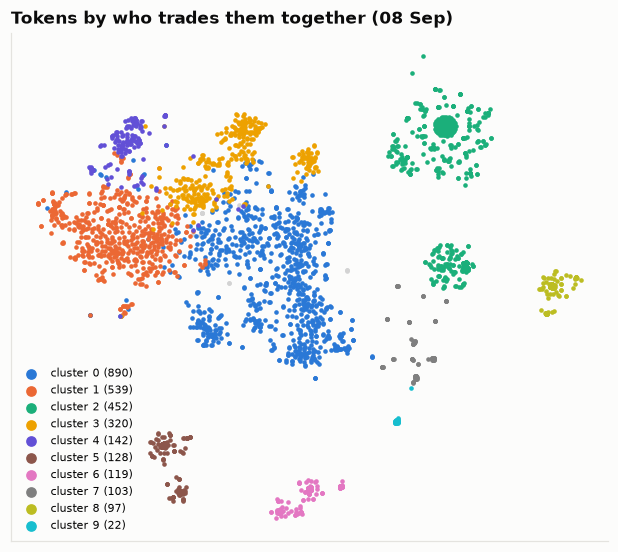

In [9]:
coords = tm.layout(graph, 3000)
coords["cluster"] = coords["token"].map(cluster_of)
largest = cluster_of.value_counts().index[:10]
fig, ax = plt.subplots(figsize=(7, 6))
other = coords[~coords["cluster"].isin(largest)]
ax.scatter(other["x"], other["y"], s=4, color="lightgrey")
palette = plots.SERIES + ["#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]
for slot, c in enumerate(largest):
    part = coords[coords["cluster"] == c]
    ax.scatter(part["x"], part["y"], s=4, color=palette[slot % len(palette)], label=f"cluster {c} ({len(part)})")
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f"Tokens by who trades them together ({T_MAP:%d %b})")
ax.legend(fontsize=7, markerscale=3, loc="best")
plt.show()

## 6. Copycats

Pairs of tokens in one cluster whose readable symbols are equal or one edit apart, at the last point of each part.
Their collapse rate against tokens of the same age comes with WP13's label.

In [10]:
rows, examples = [], None
for part in ("dev_a", "dev_b", "test"):
    t = pc.POINTS[part][-1]
    g = tm.similarity_graph(pc.load_task(legs, t), min_accounts=tm.MIN_ACCOUNTS)
    pairs = tm.copycats(tm.clusters(g, RESOLUTION), symbol)
    rows.append({"part": part, "point": t, "tokens_in_clusters": len(g.tokens), "copycat_pairs": len(pairs),
                 "same_symbol": int((pairs["distance"] == 0).sum()), "tokens_involved": len(set(pairs["token_a"]) | set(pairs["token_b"]))})  # fmt: skip
    if part == "test":
        examples = pairs
pd.DataFrame(rows)

,part,point,tokens_in_clusters,copycat_pairs,same_symbol,tokens_involved
0,dev_a,2026-07-20 00:00:00+00:00,2076,606,186,591
1,dev_b,2026-08-11 00:00:00+00:00,2526,805,304,875
2,test,2026-09-08 00:00:00+00:00,2827,2803,1449,1450


In [11]:
born = tokens.set_index("token_id")["first_timestamp"]
examples.assign(symbol_a=examples["token_a"].map(name), symbol_b=examples["token_b"].map(name),
                launched_hours_apart=(examples["token_b"].map(born) - examples["token_a"].map(born)).abs().dt.total_seconds() / 3600).head(15)  # fmt: skip

,token_a,token_b,cluster,distance,symbol_a,symbol_b,launched_hours_apart
0,7,2901,0,1,Hold,HOLY,12.877
1,32,1298,0,0,wojak,WOJAK,0.643
2,38,4369,0,1,LCAI,LBAI,28.333
3,49,847,0,0,DOGEUS,DOGEUS,0.460
4,67,50810,0,1,LMEOW,MEOW,"1,637.653"
5,67,54587,0,0,LMEOW,LMEOW,"1,814.287"
6,72,836,0,1,TRB,TRX,14.200
7,72,5798,0,1,TRB,TRX,22.060
8,83,532,0,0,LUNA,LUNA,0.350
9,87,935,0,1,KNX,ENX,2.267


## 7. Data for the explorer

`explorer/token_map.json`: the map at the last test point with each token's symbol, cluster, accounts and 10
related tokens. Tokens only; no account appears.

In [12]:
full_graph = tm.similarity_graph(task)  # all tokens, as in the check of section 3
related_lists = {int(tok): [name(r) for r in tm.related(full_graph, tok)] for tok in coords["token"]}
out = {
    "point": f"{T_MAP:%Y-%m-%d}",
    "resolution": RESOLUTION,
    "tokens": [{"name": name(r.token), "x": round(float(r.x), 2), "y": round(float(r.y), 2),
                "cluster": None if pd.isna(r.cluster) else int(r.cluster), "accounts": int(r.accounts),
                "related": related_lists[int(r.token)]} for r in coords.itertuples()],  # fmt: skip
    "clusters": cluster_table.head(30).to_dict("records"),
    "check": {part: comparisons[part].set_index("model").loc["related", ["mean_difference", "interval_low", "interval_high"]].round(4).to_dict()
              for part in comparisons},  # fmt: skip
    "hit_rates": check.groupby("part")[["related", "popular"]].mean().round(4).to_dict("index"),
}
path = td.PROJECT_DIR.parent.parent / "explorer" / "token_map.json"
path.write_text(json.dumps(out))
print(f"Written {path.name}: {len(out['tokens']):,} tokens, {path.stat().st_size / 1e6:.1f} MB")

Written token_map.json: 2,827 tokens, 0.5 MB


## 8. What this shows

- **The related-token check fails its criterion.** An account's next new token is among the first token's 10
  related tokens 8.0% of the time on Dev B and 9.3% on test, against 8.1% and 9.5% for the 10 most popular tokens:
  −0.001 (interval −0.009 to +0.006) on Dev B, 5 of 11 points; −0.002 on test, 7 of 14. At the Dev A point run for
  timing the related list was clearly ahead (10.4% against 4.8%), but the popular list is much stronger on Dev B
  and test, as the baseline of the project itself was (recall 0.075 on Dev A, 0.094 on Dev B, 0.108 on test).
- **The two lists find different tokens.** Only 1.5-2.2% of accounts are hit by both, so each list finds about
  four-fifths of its hits where the other misses: the related list captures co-adoption that popularity does not,
  it is just not more often right. This matches the project's main result, where neither neighbours nor popularity
  alone was enough and the blend of the two won.
- **Clusters are moderately stable.** Resolutions 1 and 2 agree between points two weeks apart at an adjusted Rand
  index of about 0.52; 2 was chosen (0.528), with 72 clusters at Dev A and 13 at the last test point, the largest
  holding 22% of the tokens at Dev A. The coarsest resolution (0.5) is not stable at all (0.04).
- **What the clusters are.** At the last test point: a large meme-token cluster, a cluster of established tokens
  (WBTC, DAI, wstETH), one of large caps (UNI, LINK, SHIB), and several small clusters of 100-450 tokens traded by
  only 200-560 accounts each, among them a cluster of tokenized stock tickers (MSTR, NET, LULU). Those small,
  many-token clusters look automated: their accounts are 25-29% members of WP10's farm groups, against 1-2% in the
  large clusters. No cluster is a farm target by the stated rule (more than half farm members).
- **Copycats are common.** 606 (Dev A), 805 (Dev B) and 2,803 (test) pairs of tokens in one cluster have equal or
  nearly equal symbols; 186, 304 and 1,449 have the same symbol, and several same-symbol pairs were launched within
  an hour of each other (wojak/WOJAK, LUNA, DOGEUS). One-edit matches on short symbols (TRB/TRX) are mostly
  coincidence, so the same-symbol count is the cleaner number. Whether copycats collapse more often is checked with
  WP13's label.
- **The map** of the last test point is in the explorer's "Token map" view, with each token's related list.